<a href="https://colab.research.google.com/github/Say1309/churn_fintech_model/blob/main/churn_fintech_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo Churn

**¿Qué es churn?**

Churn=fuga de clientes. Vienes del inglés "to churn". En fintech, un cliente hizo churn cuando cancela su cuenta, deja de usar la app o simplemente desaparece.

Se mide asi:

Churn rate = clientes que se fueron este mes / clientes que tenías al inicio del mes

Para analizar los datos usaremos las librerias pandas, numpy,  matplotlib y seaborn.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import warnings
warnings.filterwarnings('ignore')

print("✅ Librerías listas")

✅ Librerías listas


**Generar datos sintéticos**

Para este ejercicio generamos datos aleatorios para una muestra de 1000 clientes.

Definimos el engagement = qué tanto un cliente interactúa con tu producto en base a la siguiente regla del negocio: si un cliente tiene pocas transacciones, suma 0.3 a su probabilidad de irse. Si lleva más de 30 días sin entrar, suma otro 0.3

In [ ]:
np.random.seed(42)
n = 1000

df = pd.DataFrame({
    'meses_cliente':       np.random.randint(1, 36, n),
    'transacciones_mes':   np.random.randint(0, 30, n),
    'saldo_promedio':      np.random.uniform(0, 50000, n).round(2),
    'dias_ultimo_login':   np.random.randint(0, 90, n),
    'pagos_tardios':       np.random.randint(0, 5, n),
    'productos_contratados': np.random.randint(1, 5, n),
    'edad':                np.random.randint(18, 65, n),
})

# Lógica de churn: se van clientes con poco engagement y pagos tardíos
prob_churn = (
    (df['transacciones_mes'] < 5).astype(int) * 0.3 +
    (df['dias_ultimo_login'] > 30).astype(int) * 0.3 +
    (df['pagos_tardios'] > 2).astype(int) * 0.2 +
    (df['saldo_promedio'] < 5000).astype(int) * 0.2
)
df['churn'] = (prob_churn + np.random.uniform(0, 0.3, n) > 0.5).astype(int)

print(f"✅ Dataset creado: {df.shape[0]} clientes, {df['churn'].mean():.1%} churn rate")
df.head()

✅ Dataset creado: 1000 clientes, 52.4% churn rate


,meses_cliente,transacciones_mes,saldo_promedio,dias_ultimo_login,pagos_tardios,productos_contratados,edad,churn
0,29,13,1519.35,62,4,2,62,1
1,15,8,46547.43,23,2,4,28,0
2,8,7,34476.34,12,3,4,31,0
3,21,1,33825.67,10,3,2,19,1
4,19,12,10783.76,50,0,1,57,0


**Explorar los datos**

Analizamos los datos del dataset creado

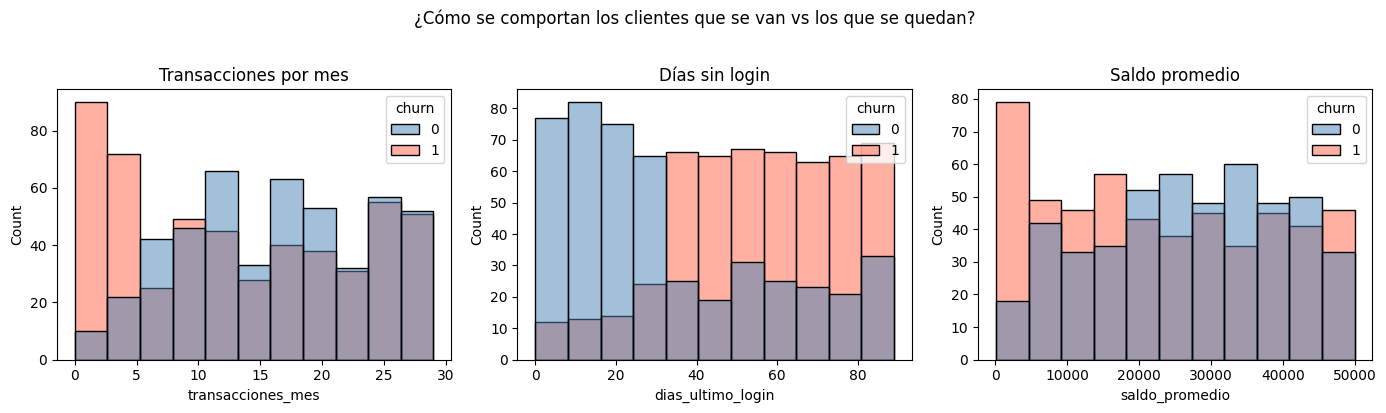


Clientes que se quedan: 476
Clientes que se van:    524


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.histplot(data=df, x='transacciones_mes', hue='churn', ax=axes[0], palette=['steelblue','tomato'])
axes[0].set_title('Transacciones por mes')

sns.histplot(data=df, x='dias_ultimo_login', hue='churn', ax=axes[1], palette=['steelblue','tomato'])
axes[1].set_title('Días sin login')

sns.histplot(data=df, x='saldo_promedio', hue='churn', ax=axes[2], palette=['steelblue','tomato'])
axes[2].set_title('Saldo promedio')

plt.suptitle('¿Cómo se comportan los clientes que se van vs los que se quedan?', y=1.02)
plt.tight_layout()
plt.show()

print(f"\nClientes que se quedan: {(df['churn']==0).sum()}")
print(f"Clientes que se van:    {(df['churn']==1).sum()}")

**Entrenar el modelo**

¿Qué es Random Forest y por qué lo usé?
Primero entiende un árbol de decisión. Random Forest = construye 100 árboles distintos, cada uno entrenado con una muestra aleatoria de los datos y variables. Luego hace votación: si 80 de los 100 dicen "se va", el modelo dice "se va". Eso lo hace mucho más robusto.


In [ ]:
X = df.drop('churn', axis=1)
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

modelo = RandomForestClassifier(n_estimators=100, random_state=42)
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)
auc = roc_auc_score(y_test, modelo.predict_proba(X_test)[:,1])

print(f"✅ Modelo entrenado")
print(f"\nAUC-ROC: {auc:.3f}  (entre más cercano a 1.0, mejor)")
print(f"\n{classification_report(y_test, y_pred, target_names=['Se queda','Se va'])}")

✅ Modelo entrenado

AUC-ROC: 0.937  (entre más cercano a 1.0, mejor)

              precision    recall  f1-score   support

    Se queda       0.78      0.86      0.82        83
       Se va       0.89      0.83      0.86       117

    accuracy                           0.84       200
   macro avg       0.84      0.84      0.84       200
weighted avg       0.84      0.84      0.84       200



**¿Qué es AUC-ROC?**

Es la métrica más usada para modelos de clasificación como este.
El modelo no dice "se va" o "se queda" directamente — calcula una probabilidad, por ejemplo 0.73. Tú decides el umbral: si > 0.5 → "se va".
ROC es una curva que grafica qué tan bien separa el modelo los dos grupos conforme mueves ese umbral. AUC es el área bajo esa curva.

AUC = 0.5 → el modelo no sirve, es como lanzar una moneda
AUC = 0.7 → aceptable
AUC = 0.9 → muy bueno
AUC = 1.0 → perfecto (sospechoso, probablemente hay fuga de datos)

## ¿Qué significa esto para el negocio?

**AUC-ROC: 0.937** — El modelo distingue correctamente entre clientes que se van
y los que se quedan el 93.7% de las veces. Un modelo random daría 0.5, uno perfecto daría 1.0.

**Precision (Se va): 89%** — Cuando el modelo lanza una alerta de churn, acierta 9 de cada 10 veces.
Útil si retener al cliente es costoso (llamadas, descuentos grandes).

**Recall (Se va): 83%** — El modelo detecta 8 de cada 10 clientes que realmente se irían.
El 17% restante se "escapa" sin ser detectado.

**¿Qué haría una fintech con esto?**
Segmentar a los clientes con probabilidad de churn > 70% y activar campañas de retención
antes de que cancelen: notificaciones, descuentos personalizados, o llamada de un ejecutivo.

**¿Qué factores predicen más el churn?**

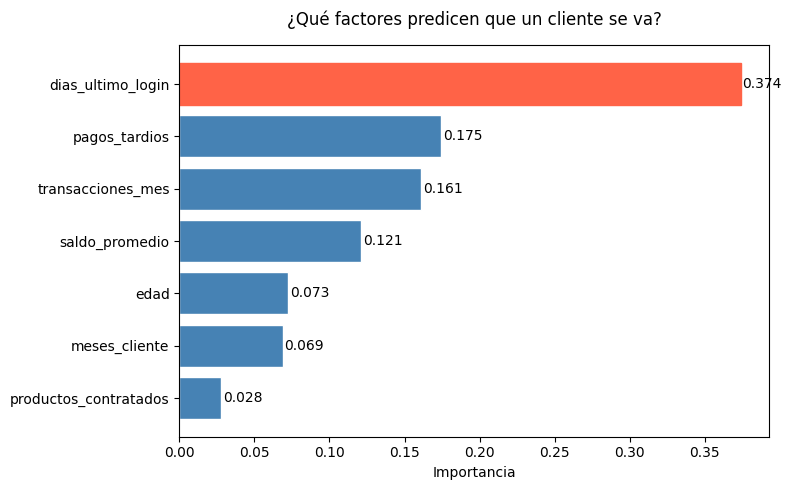

In [ ]:
importancias = pd.DataFrame({
    'variable': X.columns,
    'importancia': modelo.feature_importances_
}).sort_values('importancia', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(importancias['variable'], importancias['importancia'],
               color='steelblue', edgecolor='white')

# Colorear la más importante
bars[-1].set_color('tomato')

ax.set_xlabel('Importancia')
ax.set_title('¿Qué factores predicen que un cliente se va?', pad=15)

for bar, val in zip(bars, importancias['importancia']):
    ax.text(val + 0.001, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=10)

plt.tight_layout()
plt.show()

## Interpretación del negocio

El modelo nos dice qué variables "pesan" más al predecir churn:

- **saldo_promedio** es el predictor más fuerte — clientes con poco saldo tienen
  mayor riesgo de irse.
- **dias_ultimo_login** y **transacciones_mes** reflejan engagement —
  un cliente inactivo es un cliente en riesgo.
- **pagos_tardios** indica problemas financieros que preceden al churn.

**Acción concreta:** monitorear semanalmente clientes con saldo < $5,000
Y más de 30 días sin login → son el segmento de mayor riesgo.

**Predecir un cliente nuevo**

In [ ]:
cliente_nuevo = pd.DataFrame([{
    'meses_cliente': 3,
    'transacciones_mes': 2,
    'saldo_promedio': 1500,
    'dias_ultimo_login': 45,
    'pagos_tardios': 3,
    'productos_contratados': 1,
    'edad': 25
}])

prob = modelo.predict_proba(cliente_nuevo)[0][1]
nivel = "🔴 ALTO" if prob > 0.7 else "🟡 MEDIO" if prob > 0.4 else "🟢 BAJO"

print(f"Probabilidad de churn: {prob:.1%}")
print(f"Nivel de riesgo: {nivel}")
print()
if prob > 0.7:
    print("→ Acción recomendada: contactar al cliente esta semana con oferta de retención")
elif prob > 0.4:
    print("→ Acción recomendada: enviar notificación personalizada")
else:
    print("→ Acción recomendada: monitoreo rutinario")

Probabilidad de churn: 100.0%
Nivel de riesgo: 🔴 ALTO

→ Acción recomendada: contactar al cliente esta semana con oferta de retención
